# Bike Sharing Demand Analysis
### Exploring the relationship between weather, holidays, and hourly rentals
**Azaria Syahla Fitan Adibah** · Data Analytics Portfolio

Originally developed for a Dicoding data analysis project. This portfolio revision makes the workflow portable and refines the interpretation of the results.

## 1. Business questions
1. How do hourly rentals differ between holidays and non-holidays?
2. How does rental demand vary across recorded weather conditions?
3. How sensitive are these comparisons to removing high-demand hours?

This is a descriptive analysis of historical observations, not a causal study or a forecasting model.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titleweight": "bold"})

# Run from the repository root, or attach the dataset to a Kaggle notebook.
candidates = [Path("Bike-sharing-dataset/hour.csv"), Path("hour.csv")]
if Path("/kaggle/input").exists():
    candidates.extend(sorted(Path("/kaggle/input").rglob("hour.csv")))
existing = [path for path in candidates if path.is_file()]
if not existing:
    raise FileNotFoundError("Attach the Bike Sharing dataset containing hour.csv, or run from the repository root.")
if len(existing) > 1:
    raise ValueError(f"Multiple hour.csv files found. Set data_path explicitly: {existing}")
data_path = existing[0]
df = pd.read_csv(data_path, parse_dates=["dteday"])
print(f"Loaded {len(df):,} hourly observations and {df.shape[1]} columns.")
print(f"Period: {df.dteday.min().date()} to {df.dteday.max().date()}")
print(df.head().to_string(index=False))

Loaded 17,379 hourly observations and 17 columns.
Period: 2011-01-01 to 2012-12-31
 instant     dteday  season  yr  mnth  hr  holiday  weekday  workingday  weathersit  temp  atemp  hum  windspeed  casual  registered  cnt
       1 2011-01-01       1   0     1   0        0        6           0           1  0.24 0.2879 0.81        0.0       3          13   16
       2 2011-01-01       1   0     1   1        0        6           0           1  0.22 0.2727 0.80        0.0       8          32   40
       3 2011-01-01       1   0     1   2        0        6           0           1  0.22 0.2727 0.80        0.0       5          27   32
       4 2011-01-01       1   0     1   3        0        6           0           1  0.24 0.2879 0.75        0.0       3          10   13
       5 2011-01-01       1   0     1   4        0        6           0           1  0.24 0.2879 0.75        0.0       0           1    1


## 2. Data quality and preparation
`cnt` is the total number of rentals in a recorded hour. `holiday=0` means **non-holiday**, which includes weekends; it does not mean working day. Weather codes are categories defined in the dataset documentation, not invalid numerical values.

High rental counts are retained in the primary analysis because a large value alone does not establish a recording error. The original IQR-filtered approach is reproduced separately as a sensitivity check.

In [2]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate date-hour pairs:", int(df.duplicated(["dteday", "hr"]).sum()))
assert df["holiday"].isin([0, 1]).all()
assert df["weathersit"].isin([1, 2, 3, 4]).all()
assert (df["cnt"] == df["casual"] + df["registered"]).all()
assert (df["cnt"] >= 0).all()
print(df["cnt"].describe().round(2).to_string())
print("Weather observation counts:")
print(df["weathersit"].value_counts().sort_index().to_string())

q1, q3 = df["cnt"].quantile([0.25, 0.75])
iqr = q3 - q1
filtered = df.loc[df["cnt"].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)].copy()
print(f"IQR sensitivity sample: {len(filtered):,} rows; {len(df)-len(filtered):,} excluded.")

Missing values: 0
Duplicate rows: 0
Duplicate date-hour pairs: 0
count    17379.00
mean       189.46
std        181.39
min          1.00
25%         40.00
50%        142.00
75%        281.00
max        977.00
Weather observation counts:
weathersit
1    11413
2     4544
3     1419
4        3
IQR sensitivity sample: 16,874 rows; 505 excluded.


## 3. Rental distribution

Skewness, full sample: 1.277; IQR-filtered: 0.933


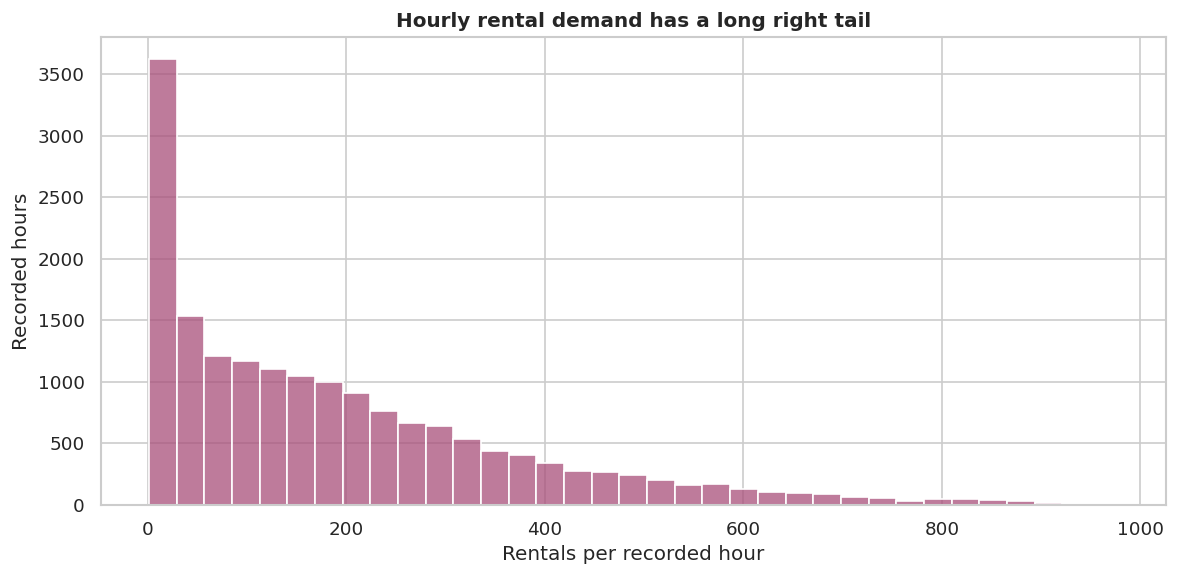

In [3]:
fig, ax = plt.subplots()
sns.histplot(data=df, x="cnt", bins=35, color="#a84f7a", ax=ax)
ax.set(title="Hourly rental demand has a long right tail", xlabel="Rentals per recorded hour", ylabel="Recorded hours")
plt.tight_layout()
plt.show()
print(f"Skewness, full sample: {df.cnt.skew():.3f}; IQR-filtered: {filtered.cnt.skew():.3f}")

## 4. Holidays and rental demand
Compare averages alongside sample sizes. Differences may also reflect hour-of-day, season, year, and user mix; this comparison does not isolate a holiday effect.

             count    mean  median
holiday                           
Non-holiday  16879  190.43   144.0
Holiday        500  156.87    97.0


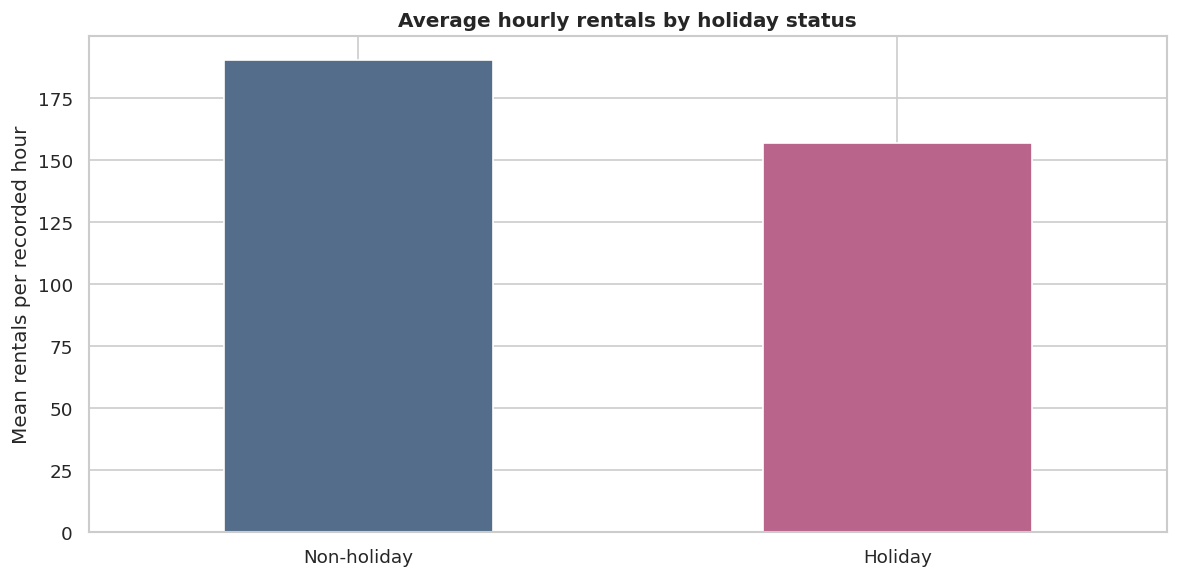

In [4]:
holiday_summary = df.groupby("holiday")["cnt"].agg(["count", "mean", "median"])
holiday_summary.index = holiday_summary.index.map({0: "Non-holiday", 1: "Holiday"})
print(holiday_summary.round(2).to_string())
fig, ax = plt.subplots()
holiday_summary["mean"].plot.bar(ax=ax, color=["#536d8a", "#b9658b"], rot=0)
ax.set(title="Average hourly rentals by holiday status", xlabel="", ylabel="Mean rentals per recorded hour")
plt.tight_layout()
plt.show()

## 5. Weather and rental demand
Weather labels follow the supplied documentation. The severe-weather group is very small, so its mean should be treated cautiously. The weather code is ordinal; a linear correlation on the code is only a rough descriptive summary.

                       count    mean  median
weathersit                                  
Clear / partly cloudy  11413  204.87   159.0
Mist / cloudy           4544  175.17   133.0
Light rain / snow       1419  111.58    63.0
Severe weather             3   74.33    36.0
Pearson correlations with hourly rentals:
temp          0.405
atemp         0.401
hum          -0.323
windspeed     0.093
holiday      -0.031
weathersit   -0.142


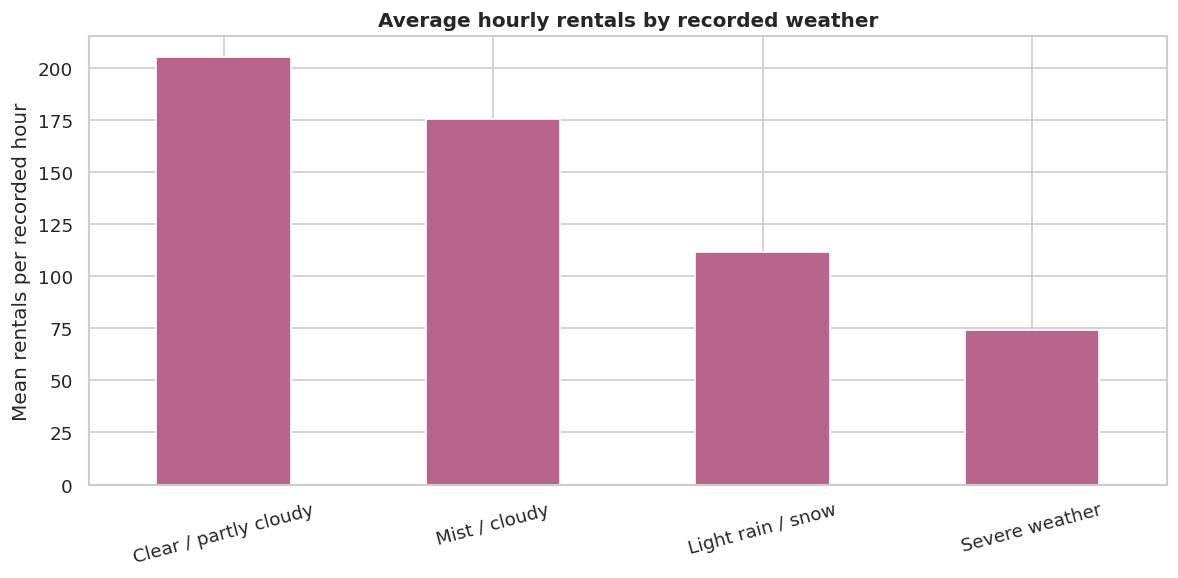

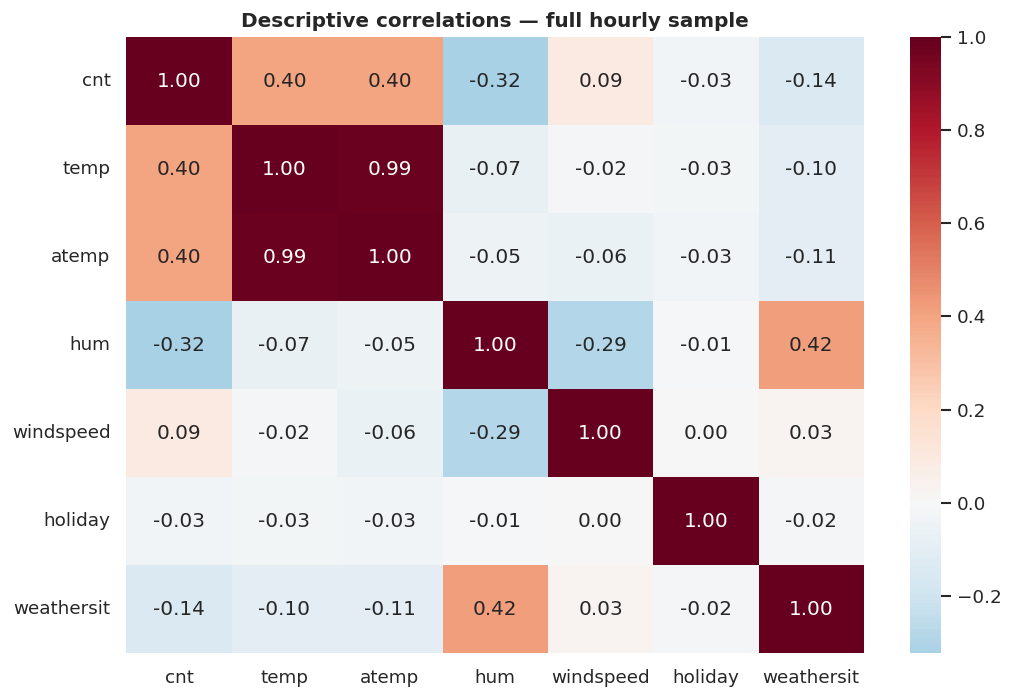

In [5]:
weather_labels = {1: "Clear / partly cloudy", 2: "Mist / cloudy", 3: "Light rain / snow", 4: "Severe weather"}
weather_summary = df.groupby("weathersit")["cnt"].agg(["count", "mean", "median"])
weather_summary.index = weather_summary.index.map(weather_labels)
print(weather_summary.round(2).to_string())
fig, ax = plt.subplots()
weather_summary["mean"].plot.bar(ax=ax, color="#b9658b", rot=15)
ax.set(title="Average hourly rentals by recorded weather", xlabel="", ylabel="Mean rentals per recorded hour")
plt.tight_layout()
plt.show()

columns = ["cnt", "temp", "atemp", "hum", "windspeed", "holiday", "weathersit"]
print("Pearson correlations with hourly rentals:")
print(df[columns].corr()["cnt"].drop("cnt").round(3).to_string())
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(df[columns].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Descriptive correlations — full hourly sample")
plt.tight_layout()
plt.show()

## 6. Sensitivity to the original IQR filter

In [6]:
comparison = pd.concat({"Full sample": df.groupby("holiday")["cnt"].mean(),
                        "IQR-filtered": filtered.groupby("holiday")["cnt"].mean()}, axis=1)
comparison.index = comparison.index.map({0: "Non-holiday", 1: "Holiday"})
print(comparison.round(2).to_string())
weather_comparison = pd.concat({"Full sample": df.groupby("weathersit")["cnt"].mean(),
                                "IQR-filtered": filtered.groupby("weathersit")["cnt"].mean()}, axis=1)
weather_comparison.index = weather_comparison.index.map(weather_labels)
print(weather_comparison.round(2).to_string())
print("Correlation sensitivity:")
print(pd.DataFrame({"Full sample": df[columns].corr()["cnt"],
                    "IQR-filtered": filtered[columns].corr()["cnt"]}).drop("cnt").round(3).to_string())

             Full sample  IQR-filtered
holiday                               
Non-holiday       190.43        173.26
Holiday           156.87        154.71
                       Full sample  IQR-filtered
weathersit                                      
Clear / partly cloudy       204.87        185.31
Mist / cloudy               175.17        162.63
Light rain / snow           111.58        106.05
Severe weather               74.33         74.33
Correlation sensitivity:
            Full sample  IQR-filtered
temp              0.405         0.402
atemp             0.401         0.398
hum              -0.323        -0.327
windspeed         0.093         0.098
holiday          -0.031        -0.020
weathersit       -0.142        -0.139


## 7. Findings and practical implications
- **Holiday comparison:** mean rentals are 190.43 per recorded hour on non-holidays and 156.87 on holidays. Non-holidays include weekends.
- **Weather comparison:** clear or partly cloudy hours average 204.87 rentals, compared with 111.58 during light rain or snow. These are observed associations.
- **Sparse conditions:** severe weather has only 3 recorded hours; avoid generalizing its average.
- **Operational use:** explore weather-aware staffing and bicycle availability, then validate plans by season and hour before changing operations.
- **Data preparation matters:** filtering high-demand hours changes group means and correlations. Retain valid peaks when planning capacity.

### Limitations
No hypothesis tests, confounder adjustment, causal identification, or predictive evaluation are performed. Small correlations do not prove the absence of a relationship. The data are historical (2011–2012), and averages are calculated across recorded hours rather than a complete reconstructed calendar.

## Dataset attribution
Bike Sharing Dataset, Hadi Fanaee-T and Joao Gama. Capital Bikeshare observations from Washington, D.C., 2011–2012.

Fanaee-T, H. and Gama, J. (2013). *Event labeling combining ensemble detectors and background knowledge*. DOI: 10.1007/s13748-013-0040-3.

The original dataset documentation is retained in `Bike-sharing-dataset/Readme.txt`.